In [1]:
import kagglehub

path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Path to dataset files: /kaggle/input/mnist-dataset


In [6]:
!pip install idx2numpy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for idx2numpy: filename=idx2numpy-1.2.3-py3-none-any.whl size=8001 sha256=65f78537cceceb8169ecac5895f55de27bac5218a603253dc5803877ba599c3d
  Stored in directory: /root/.cache/pip/wheels/3a/19/2b/d62d9c881cc383ad62fc12a882040d1900c19b5115b6a41e50
Successfully built idx2numpy


In [7]:
import os
import numpy as np
import idx2numpy
import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline


In [12]:
X_train = idx2numpy.convert_from_file(os.path.join(path, 'train-images.idx3-ubyte'))
y_train = idx2numpy.convert_from_file(os.path.join(path, 'train-labels.idx1-ubyte'))
X_test = idx2numpy.convert_from_file(os.path.join(path, 't10k-images.idx3-ubyte'))
y_test = idx2numpy.convert_from_file(os.path.join(path, 't10k-labels.idx1-ubyte'))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape: (10000, 28, 28)
y_test shape: (10000,)


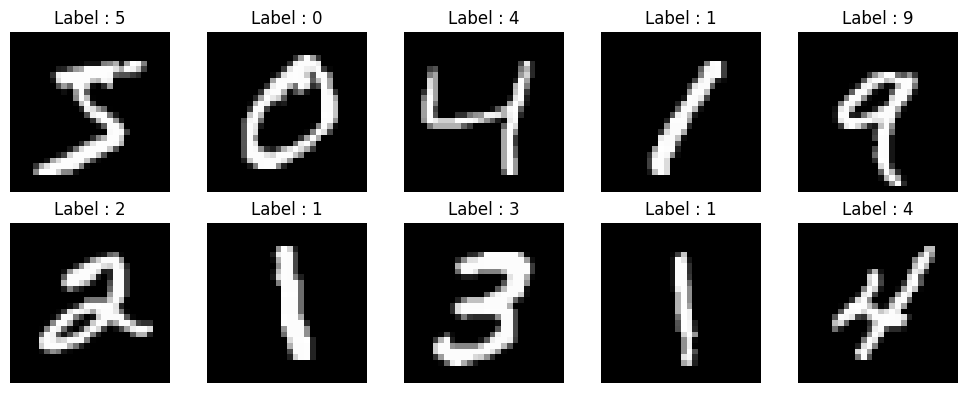

In [48]:
plt.figure(figsize=(10,4))

for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(X_train[i],cmap='gray')
  plt.title(f"Label : {y_train[i]}")
  plt.axis('off')

plt.tight_layout()
plt.show()


In [15]:
X_train = X_train.astype('float32')/255.0
X_test = X_test.astype('float32')/255.0

In [23]:
len(X_train[0])

28

In [25]:
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras  import layers

model  = keras.Sequential(
    [
        layers.Input(shape=(28,28)),

        layers.Flatten(),

        layers.Dense(128,activation='relu'),

        layers.Dense(64, activation='relu'),

        layers.Dense(10,activation='softmax')

    ]
)

In [26]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
model.compile(optimizer='adam',loss="sparse_categorical_crossentropy", metrics=['accuracy'])

In [29]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss',patience=3,min_delta=0.001,restore_best_weights=True,verbose=1)

In [30]:
history = model.fit(X_train,y_train,epochs=10, validation_split=0.2,batch_size=32,verbose=1,callbacks=[early_stopping])

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9227 - loss: 0.2646 - val_accuracy: 0.9598 - val_loss: 0.1330
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9666 - loss: 0.1117 - val_accuracy: 0.9672 - val_loss: 0.1094
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9765 - loss: 0.0764 - val_accuracy: 0.9722 - val_loss: 0.0927
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9816 - loss: 0.0577 - val_accuracy: 0.9703 - val_loss: 0.1036
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9855 - loss: 0.0452 - val_accuracy: 0.9734 - val_loss: 0.0935
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9885 - loss: 0.0348 - val_accuracy: 0.9748 - val_loss: 0.1021
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.


In [33]:
y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [34]:
test_loss,test_accuracy = model.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9722 - loss: 0.0892


In [39]:
print(test_accuracy)

0.9721999764442444


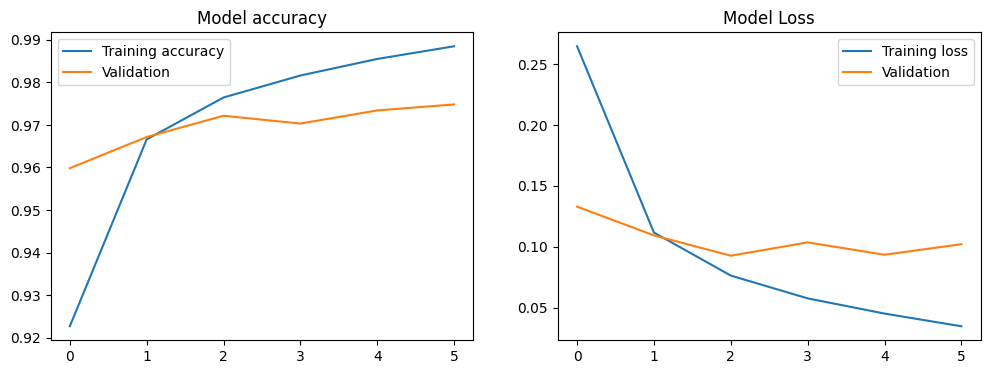

In [42]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'], label="Validation")

plt.title("Model accuracy")

plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Model Loss")
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


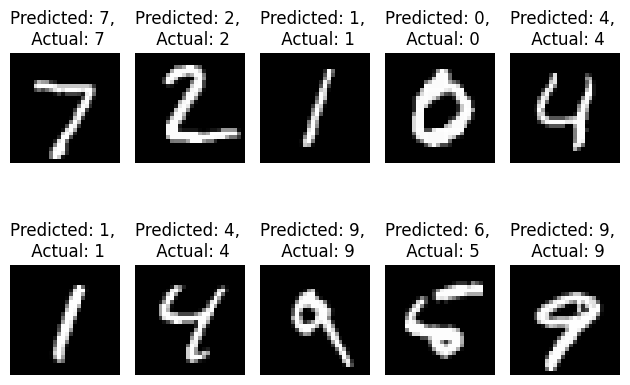

In [44]:
predictions = model.predict(X_test[:10])

for i in range(10):
  predict_digit = np.argmax(predictions[i])
  actual_digit = y_test[i]

  plt.subplot(2,5,i+1)
  plt.imshow(X_test[i],cmap='gray')

  plt.title(f"Predicted: {predict_digit}, \n Actual: {actual_digit}")
  plt.axis('off')

plt.tight_layout()
plt.show()